# 第07章 B1组（G19）独立验证

2026-11-11 · 首轮阶段验证。全部代码由本次 Codex 助手辅助编写、实际执行；G19 人工签认尚待补充。被审固定提交：`0f70a61edb808d046aad482b51a5f35ce93bf3d2`。

A1：`A1-G1-正文.ipynb`；A2：`工作-A2-G6/A2-G6-实验.ipynb` 及两版正文。这里的独立测试不代替 A 原文件的顺序运行；原稿运行结果记录在验证报告。7.3 是补充测试，不计本阶段必做完整性。

本 Notebook 自包含，只需课程基础依赖，无需 A 的缺失脚本、Windows 字体或制图附加库。按顺序重启运行即可；失败案例用断言确认预期，避免红色异常。

In [1]:
import sys, platform, json, math, importlib.metadata as im
import numpy as np
import pandas as pd
import scipy
from scipy.stats import binom, norm
from scipy.linalg import solve_banded
from numpy.polynomial import Polynomial
import matplotlib.pyplot as plt
from IPython.display import display
RESULTS = {}
ENV = {'python':platform.python_version(), 'system':platform.system(),
       'machine':platform.machine(), 'venv_active':sys.prefix != sys.base_prefix,
       'packages':{k:im.version(k) for k in ['numpy','scipy','matplotlib','pandas','sympy','nbformat','nbclient','ipykernel']}}
print(json.dumps(ENV,ensure_ascii=False,indent=2))
assert ENV['venv_active']

{
  "python": "3.12.10",
  "system": "Darwin",
  "machine": "arm64",
  "venv_active": true,
  "packages": {
    "numpy": "1.26.4",
    "scipy": "1.14.1",
    "matplotlib": "3.9.2",
    "pandas": "2.2.3",
    "sympy": "1.13.3",
    "nbformat": "5.10.4",
    "nbclient": "0.10.2",
    "ipykernel": "6.29.5"
  }
}


## T01 · 7.1：有限类泛化界的解析与精确概率检查

固定有界 Bernoulli 损失，独立同分布；用二项分布精确计算偏差越界概率，与 Hoeffding 上界比较。此处无拟合模型，检验的是基础概率项。K=21 时用并集给一致界，不能把有限模拟当成定理证明。

In [2]:
K, delta, p = 21, 0.05, 0.3
bound_rows=[]
for n in [20,80,320]:
    eps=np.sqrt(np.log(2*K/delta)/(2*n))
    k=np.arange(n+1)
    exact=float(binom.pmf(k,n,p)[np.abs(k/n-p)>eps].sum())
    upper=float(2*np.exp(-2*n*eps**2))
    assert exact <= upper + 1e-12
    bound_rows.append({'n':n,'uniform_radius':float(eps), 'single_exact_tail':exact,'single_Hoeffding_upper':upper})
assert abs(bound_rows[0]['uniform_radius']/bound_rows[1]['uniform_radius']-2)<1e-12
RESULTS['T01']=bound_rows
display(pd.DataFrame(bound_rows))

,n,uniform_radius,single_exact_tail,single_Hoeffding_upper
0,20,0.410287,0.000043,0.002381
1,80,0.205143,0.000061,0.002381
2,320,0.102572,0.000075,0.002381


## T02 · 7.1：A2 阈值分类器的独立参考与重复试验

X∼U[0,1]，真阈值 a=0.53，标签独立翻转概率 η=0.10；候选阈值 t∈{0,0.05,…,1}。未翻转时误分类区长度 |t−a|，故解析风险 R(t)=η+(1−2η)|t−a|。用区间积分的独立算法复核；随后固定种子 20261024，按 A2 数值代码的抽样顺序复算（不调用其制图代码）。输出是 B 重算，不是 A 原 Notebook 已通过。

In [3]:
thresholds=np.arange(21)/20; a=0.53; eta=0.1
risks=eta+(1-2*eta)*np.abs(thresholds-a)
def risk_by_intervals(t):
    cuts=sorted(set([0.0,float(t),a,1.0])); out=0.0
    for l,r in zip(cuts[:-1],cuts[1:]):
        mid=(l+r)/2
        out+=(r-l)*(eta if (mid>=t)==(mid>=a) else 1-eta)
    return out
ref=np.array([risk_by_intervals(t) for t in thresholds])
np.testing.assert_allclose(risks,ref,atol=1e-15,rtol=0)
rng=np.random.default_rng(20261024)
def draw(n):
    x=rng.random(n); y=np.logical_xor(x>=a,rng.random(n)<eta)
    return x,y
def errors(x,y):return ((x[:,None]>=thresholds)!=y[:,None]).mean(axis=0)
e=errors(*draw(80)); selected=int(np.argmin(e))
ft=np.array([errors(*draw(200))[selected] for _ in range(200)])
fixed={'threshold':float(thresholds[selected]),'train_error':float(e[selected]),
       'analytic_risk':float(risks[selected]),'test_mean':float(ft.mean()),'test_sd':float(ft.std(ddof=1))}
rows=[]
for n in [20,50,100,200,500,1000]:
    vals=[]
    for repeat in range(200):
        e=errors(*draw(n)); j=int(np.argmin(e)); test=errors(*draw(2000))[j]
        vals.append([e[j],test,risks[j],np.max(np.abs(e-risks))])
    vals=np.array(vals); radius=float(np.sqrt(np.log(2*21/0.05)/(2*n)))
    rows.append({'n':n,'train_mean':float(vals[:,0].mean()),'test_mean':float(vals[:,1].mean()),
                 'risk_mean':float(vals[:,2].mean()),'uniform_radius':radius,
                 'sup_q95':float(np.quantile(vals[:,3],.95)), 'violations':int((vals[:,3]>radius).sum()),'repeats':200})
RESULTS['T02']={'fixed':fixed,'rows':rows,'risk_reference_max_error':float(np.max(np.abs(risks-ref)))}
print(json.dumps(fixed,ensure_ascii=False,indent=2));display(pd.DataFrame(rows))

{
  "threshold": 0.5,
  "train_error": 0.0875,
  "analytic_risk": 0.12400000000000003,
  "test_mean": 0.12225000000000001,
  "test_sd": 0.0225829014341809
}


,n,train_mean,test_mean,risk_mean,uniform_radius,sup_q95,violations,repeats
0,20,0.095000,0.145635,0.14512,0.410287,0.28460,0,200
1,50,0.109400,0.127088,0.12736,0.259488,0.20400,0,200
2,100,0.109100,0.121062,0.12028,0.183486,0.13400,0,200
3,200,0.113675,0.118890,0.11976,0.129744,0.08900,0,200
4,500,0.115300,0.118110,0.11824,0.082057,0.05620,0,200
5,1000,0.114885,0.116015,0.11692,0.058023,0.03905,0,200


## T03 · 7.1：A1 VC 界推导的不等号

A1 定理 7.1.7 证明已写 A≤nε²/8（A>0），后续应为 ε≥√(8A/n)，或取等号选半径。下例用阈值的一半，展示它并不能让该尾概率上界小于 δ。此项只定位证明中的代数错误，不声称最终标准界本身错误。

In [4]:
n,d,delta=100,1,0.05
A=d*np.log(2*np.e*n/d)+np.log(4/delta)
radius=float(np.sqrt(8*A/n)); wrong_eps=radius/2
wrong_upper=float(4*(2*np.e*n/d)**d*np.exp(-n*wrong_eps**2/8))
correct_upper=float(4*(2*np.e*n/d)**d*np.exp(-n*radius**2/8))
assert wrong_upper>delta and np.isclose(correct_upper,delta)
RESULTS['T03']={'correct_radius':radius,'epsilon_half_radius':wrong_eps,
                'tail_bound_at_half':wrong_upper,'tail_bound_at_radius':correct_upper,'delta':delta}
print(json.dumps(RESULTS['T03'],indent=2))

{
  "correct_radius": 0.9243524869322057,
  "epsilon_half_radius": 0.46217624346610287,
  "tail_bound_at_half": 150.584701623775,
  "tail_bound_at_radius": 0.0499999999999999,
  "delta": 0.05
}


## T04 · 7.2：分布内/外误差、独立求解器与不可识别性

A2 网格协议：41 个训练点 U 网格 [−1,1]，40 个交错区内点，101 个 [2,3] 区外点；模型次数事先固定 3、5、8。参考实现使用尺度归一化的 Polynomial.fit（最小二乘/SVD），另用 Chebyshev 基比较预测。独立随机三次模型使用种子7201及41/1000/1000样本，避免把固定网格误称为完整 iid 测试。

另构造 g=sin(x)+max(x−1,0)^3：在观测区相同，在 x=3 相差8，同一预测对两者至少一个误差≥4。

In [5]:
train=np.linspace(-1,1,41); inside=(train[:-1]+train[1:])/2; outside=np.linspace(2,3,101)
poly_rows=[]
for degree in [3,5,8]:
    model=Polynomial.fit(train,np.sin(train),degree)
    alt=np.polynomial.Chebyshev.fit(train,np.sin(train),degree)
    for name,points in [('train',train),('inside',inside),('outside',outside)]:
        pred=model(points); err=pred-np.sin(points)
        np.testing.assert_allclose(pred,alt(points),atol=1e-8,rtol=1e-8)
        poly_rows.append({'degree':degree,'domain':name,'points':len(points),
                         'rmse':float(np.sqrt(np.mean(err**2))),'max_abs_error':float(np.max(np.abs(err)))})
rng=np.random.default_rng(7201); xtrain=rng.uniform(-1,1,41); xi=rng.uniform(-1,1,1000); xo=rng.uniform(2,3,1000)
model=Polynomial.fit(xtrain,np.sin(xtrain),3)
sampled=[]
for name,points in [('train',xtrain),('ID',xi),('OOD',xo)]:
    err=model(points)-np.sin(points)
    sampled.append({'domain':name,'points':len(points),'rmse':float(np.sqrt(np.mean(err**2)))})
obs=np.linspace(-1,1,1001)
assert np.array_equal(np.sin(obs),np.sin(obs)+np.maximum(obs-1,0)**3)
answers=np.array([np.sin(3),np.sin(3)+8]); assert abs(np.diff(answers)[0]-8)<1e-12
RESULTS['T04']={'grid':poly_rows,'sampled':sampled,'possible_answers_at_3':answers.tolist()}
display(pd.DataFrame(poly_rows));display(pd.DataFrame(sampled));print('不可识别性：两可能答案差8，至少一误差≥4。')

,degree,domain,points,rmse,max_abs_error
0,3,train,41,3.411224e-04,7.797462e-04
1,3,inside,40,3.120702e-04,4.774352e-04
2,3,outside,101,7.273005e-01,1.391997e+00
3,5,train,41,2.112233e-06,4.105762e-06
4,5,inside,40,1.939328e-06,3.373429e-06
5,5,outside,101,1.365272e-01,3.082572e-01
6,8,train,41,7.443460e-09,1.336228e-08
7,8,inside,40,7.051202e-09,1.367438e-08
8,8,outside,101,1.493220e-02,3.802612e-02


,domain,points,rmse
0,train,41,0.000289
1,ID,1000,0.000319
2,OOD,1000,0.739198


不可识别性：两可能答案差8，至少一误差≥4。


## T05 · 7.2：A1 域适应推导的补充条件检查

二值分类的标准界带理想联合风险 λ，不必要求条件分布相同。构造单一输入点、源域标签0/目标域标签1、候选为常数0和1；输入散度为0但λ=1，标准界仍成立。此例反驳“概念漂移使含λ的该界本身不适用”的说法，不承诺界有信息量。

正确链：R_T(h)≤R_T(h*)+R_T(h,h*)≤R_T(h*)+R_S(h,h*)+d/2≤R_S(h)+R_S(h*)+R_T(h*)+d/2。

In [6]:
rs=np.array([0.,1.]); rt=np.array([1.,0.]); divergence=0.; lam=float(np.min(rs+rt))
assert lam==1 and np.all(rt<=rs+divergence/2+lam)
RESULTS['T05']={'source_risks':rs.tolist(),'target_risks':rt.tolist(),'divergence':divergence,'lambda':lam}
print(json.dumps(RESULTS['T05'],indent=2))

{
  "source_risks": [
    0.0,
    1.0
  ],
  "target_risks": [
    1.0,
    0.0
  ],
  "divergence": 0.0,
  "lambda": 1.0
}


## T06 · 7.4：A2 原始代码单元逐字执行

以下代码完整取自 A2 实验 Notebook 零基单元39，仅删除不影响执行的作者注释与创建时间，算法、参数、随机调用和最后的打印原样保留。末句属于 A 的程序输出，B 的判断见紧随其后的 T07。

此处为原单元的分节运行；不表示整个 A2 Notebook 已顺序通过。

In [7]:
import numpy as np

# 设定随机种子
rng = np.random.default_rng(2026)

# 生成带噪 sin 数据
def generate_data(x_range, n, noise_std=0.3):
    x = rng.uniform(x_range[0], x_range[1], n)
    y = np.sin(2 * np.pi * x) + rng.normal(0, noise_std, n)
    return x, y

# 简单拟合模型（此处用真实函数 + 偏差代替，为了计算简便）
def model_predict(x):
    # 假设模型略微不准，带点整体偏移
    return np.sin(2 * np.pi * x) + 0.1 

# 计算 Split-Conformal 的 q
def compute_q(x_cal, y_cal, alpha=0.2):
    preds = model_predict(x_cal)
    residuals = np.abs(y_cal - preds)
    residuals.sort()
    n = len(residuals)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    # 防止 k 越界
    k = min(k, n) 
    return residuals[k - 1]

# 计算 PICP 和 MPIW
def evaluate_coverage(x_test, y_test, q):
    preds = model_predict(x_test)
    lower = preds - q
    upper = preds + q
    # 覆盖率 PICP
    picp = np.mean((y_test >= lower) & (y_test <= upper))
    # 平均宽度 MPIW
    mpiw = np.mean(upper - lower)
    return picp, mpiw

# 实验运行
alpha = 0.2
n_cal = 1000
n_test = 1000

# 1. 校准阶段 (域内)
x_cal, y_cal = generate_data([-1, 1], n_cal)
q = compute_q(x_cal, y_cal, alpha)

# 2. 测试阶段 (域内 vs 域外)
x_test_in, y_test_in = generate_data([-1, 1], n_test)
x_test_out, y_test_out = generate_data([2, 3], n_test)

picp_in, mpiw_in = evaluate_coverage(x_test_in, y_test_in, q)
picp_out, mpiw_out = evaluate_coverage(x_test_out, y_test_out, q)

print(f"设定的阈值 q = {q:.4f}")
print(f"域内测试: PICP = {picp_in:.4f}, MPIW = {mpiw_in:.4f}")
print(f"域外测试: PICP = {picp_out:.4f}, MPIW = {mpiw_out:.4f}")
print("结论：MPIW 没变（因为 q 没变），但域外 PICP 大幅塌陷，分布偏移破坏了可交换性假设。")

设定的阈值 q = 0.4107
域内测试: PICP = 0.8130, MPIW = 0.8213
域外测试: PICP = 0.8010, MPIW = 0.8213
结论：MPIW 没变（因为 q 没变），但域外 PICP 大幅塌陷，分布偏移破坏了可交换性假设。


In [8]:
RESULTS['T06']={'q':float(q),'ID_PICP':float(picp_in),'OOD_PICP':float(picp_out),
                'ID_MPIW':float(mpiw_in),'OOD_MPIW':float(mpiw_out),'nominal':1-alpha}
print('B1记录原单元实际数值：', json.dumps(RESULTS['T06'],ensure_ascii=False))

B1记录原单元实际数值： {"q": 0.41067278696708653, "ID_PICP": 0.813, "OOD_PICP": 0.801, "ID_MPIW": 0.8213455739341732, "OOD_MPIW": 0.8213455739341732, "nominal": 0.8}


## T07 · 7.4：独立解析覆盖率与真正改变残差的对照

A2 原实现 Y=sin(2πX)+ε，f̂=sin(2πX)+0.1，故有符号残差 ε−0.1∼N(−0.1,0.3²)，与X无关。换输入域后联合分布不再相同，但用于共形校准的分数分布相同，覆盖率可继续保持。OOD不蕴含覆盖必塌陷。

固定本次校准q的理论覆盖为 Φ((q+0.1)/0.3)−Φ((−q+0.1)/0.3)。独立对照额外令 OOD 真值增加1.5，以明确改变残差分布；这是B设计的对照，不能冒充A原代码。

{
  "fixed_q_theory_original_both_domains": 0.8054450453191193,
  "independent_original_residual_coverage": 0.8057,
  "B_constructed_shift_coverage": 0.00041,
  "B_constructed_shift_theory": 0.00048730075021852627,
  "independent_n": 100000
}


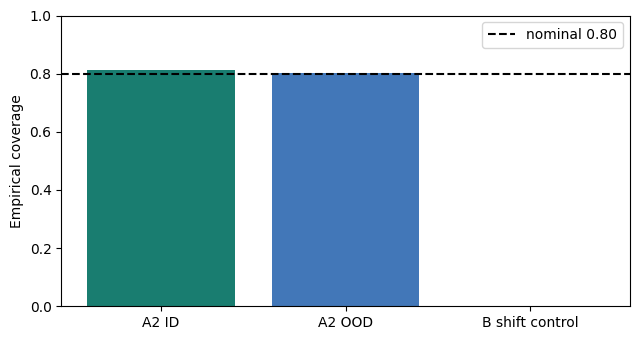

In [9]:
theory=float(norm.cdf((q+0.1)/0.3)-norm.cdf((-q+0.1)/0.3))
rng_ref=np.random.default_rng(7419); eps_ref=rng_ref.normal(0,0.3,100000)
base=float(np.mean(np.abs(eps_ref-0.1)<=q))
shift=float(np.mean(np.abs(eps_ref+1.5-0.1)<=q))
shift_theory=float(norm.cdf((q-1.4)/0.3)-norm.cdf((-q-1.4)/0.3))
assert abs(base-theory)<0.01 and abs(shift-shift_theory)<0.01
assert abs(picp_in-theory)<0.06 and abs(picp_out-theory)<0.06
assert shift<0.05
RESULTS['T07']={'fixed_q_theory_original_both_domains':theory,'independent_original_residual_coverage':base,
               'B_constructed_shift_coverage':shift,'B_constructed_shift_theory':shift_theory,
               'independent_n':len(eps_ref)}
print(json.dumps(RESULTS['T07'],ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(6.5,3.5))
labels=['A2 ID','A2 OOD','B shift control']
ax.bar(labels,[picp_in,picp_out,shift],color=['#197d70','#4277b8','#df733d'])
ax.axhline(.8,color='black',ls='--',label='nominal 0.80');ax.set_ylim(0,1)
ax.set_ylabel('Empirical coverage');ax.legend();fig.tight_layout();plt.show()

## T08 · 7.4：小校准集边界及空输入

预期 k=ceil((n+1)(1−α))>n 时 q=∞。A2 用 min(k,n) 返回最大校准残差；对连续 iid 分数，最大值的边际覆盖恰为 n/(n+1)，n=5 时仅5/6，小于目标90%。这是适用性错误，不是每次具体校准集都正好覆盖5/6。

本单元直接调用T06定义的A函数，并与B参考函数比较；B参考另外检查空数据、非法α、非有限分数。

In [10]:
def conformal_q_reference(scores,alpha):
    scores=np.asarray(scores,dtype=float)
    if scores.ndim!=1 or len(scores)==0 or not np.isfinite(scores).all():
        raise ValueError('scores must be a nonempty finite vector')
    if not 0<alpha<1: raise ValueError('alpha must lie in (0,1)')
    n=len(scores); k=int(np.ceil((n+1)*(1-alpha)))
    return float('inf') if k>n else float(np.partition(scores,k-1)[k-1])
xc=np.zeros(5); target_scores=np.arange(1.,6.); yc=model_predict(xc)+target_scores
q_a=float(compute_q(xc,yc,alpha=.1));q_b=conformal_q_reference(target_scores,.1)
assert q_a==5. and math.isinf(q_b)
assert conformal_q_reference(np.arange(1.,10.),.1)==9.
for scores,al in [([],0.1),([1.],0),([1.],1),([np.nan],.1)]:
    try:conformal_q_reference(scores,al)
    except ValueError:pass
    else:raise AssertionError('expected ValueError')
RESULTS['T08']={'n_cal':5,'alpha':.1,'A_q':q_a,'B_q':'infinity',
                'A_clipped_marginal_coverage_continuous_iid':5/6,'required':.9,
                'n9_alpha01_reference_q':9.,'invalid_input_checks':4}
print(json.dumps(RESULTS['T08'],indent=2))

{
  "n_cal": 5,
  "alpha": 0.1,
  "A_q": 5.0,
  "B_q": "infinity",
  "A_clipped_marginal_coverage_continuous_iid": 0.8333333333333334,
  "required": 0.9,
  "n9_alpha01_reference_q": 9.0,
  "invalid_input_checks": 4
}


## T09 · 7.4：重复校准，区分边际概率与一次覆盖率

独立生成2000批校准集，每批99个连续分数，200个测试分数。分数模型沿用 |N(−0.1,0.3²)|，目标90%，k=90，理论边际覆盖90/100=0.9。报告“每批覆盖率”的均值与 Monte Carlo 标准误，不能把共用一个q的全部测试点误当作独立校准试验。并列分数全零的对照显示覆盖可达1；近似等于目标的上界需要无并列或随机打破并列。

In [11]:
rng_mc=np.random.default_rng(7420); reps,ncal,ntest=2000,99,200
cal=np.abs(rng_mc.normal(-.1,.3,(reps,ncal)))
k=int(np.ceil((ncal+1)*.9));qs=np.partition(cal,k-1,axis=1)[:,k-1]
test=np.abs(rng_mc.normal(-.1,.3,(reps,ntest)))
cover=(test<=qs[:,None]).mean(axis=1)
mean=float(cover.mean());se=float(cover.std(ddof=1)/np.sqrt(reps))
assert abs(mean-k/(ncal+1))<5*se
zero_q=conformal_q_reference(np.zeros(99),.1); tied_coverage=float(np.mean(np.zeros(200)<=zero_q))
assert tied_coverage==1
RESULTS['T09']={'repeats':reps,'n_cal':ncal,'n_test_each':ntest,'rank':k,
                'exact_marginal':k/(ncal+1),'empirical_mean':mean,'MC_SE_across_calibration_batches':se,
                'batch_coverage_q025_q975':np.quantile(cover,[.025,.975]).tolist(),
                'mean_width':float(2*qs.mean()),'all_zero_tied_scores_coverage':tied_coverage}
print(json.dumps(RESULTS['T09'],ensure_ascii=False,indent=2))

{
  "repeats": 2000,
  "n_cal": 99,
  "n_test_each": 200,
  "rank": 90,
  "exact_marginal": 0.9,
  "empirical_mean": 0.8998975,
  "MC_SE_across_calibration_batches": 0.000796888331186491,
  "batch_coverage_q025_q975": [
    0.825,
    0.96
  ],
  "mean_width": 1.0510348191815047,
  "all_zero_tied_scores_coverage": 1.0
}

## T10 · 7.3补充：制造解、残差稳定性与二阶差分

补充检查不作为7.3本轮完整性门槛。u=sin(πx)，û=(1+α)u，解析上 ||e||₂=||r||₂/π²。差分使用独立带状求解器，并比较解析解误差阶。边界遗漏例 û=u+1 的内部残差零、误差非零。

A1 自己的参数化 Poisson 方案 u(x;μ)=μ²sin(πx)/π²+μx(1−x) 对所有μ都位于同一二维子空间；因此3维POD不会由于参数外推自动出现新方向。这是补充的结构检查，未运行A1缺失的MLP或ROM实现。

In [12]:
alpha_ref=.02
error_norm=abs(alpha_ref)/np.sqrt(2);residual_norm=abs(alpha_ref)*np.pi**2/np.sqrt(2)
assert np.isclose(error_norm,residual_norm/np.pi**2,rtol=1e-14)
fd=[]
for ngrid in [31,63,127,255]:
    h=1/(ngrid+1);x=np.arange(1,ngrid+1)*h
    ab=np.zeros((3,ngrid));ab[0,1:]=-1/h**2;ab[1]=2/h**2;ab[2,:-1]=-1/h**2
    u=solve_banded((1,1),ab,np.pi**2*np.sin(np.pi*x))
    err=float(np.sqrt(h*np.sum((u-np.sin(np.pi*x))**2)))
    fd.append({'n':ngrid,'h':h,'L2_error':err})
orders=[float(np.log2(fd[i]['L2_error']/fd[i+1]['L2_error'])) for i in range(len(fd)-1)]
assert all(1.99<p<2.01 for p in orders)
x=np.linspace(0,1,201);mus=np.array([.1,.2,.3,.4,.5])
S=np.sin(np.pi*x[:,None])*mus[None,:]**2/np.pi**2+x[:,None]*(1-x[:,None])*mus[None,:]
U,s,Vt=np.linalg.svd(S,full_matrices=False)
uood=np.sin(np.pi*x)/np.pi**2+x*(1-x)
proj=U[:,:2]@(U[:,:2].T@uood)
rel=float(np.linalg.norm(uood-proj)/np.linalg.norm(uood))
assert s[2]/s[0]<1e-13 and rel<1e-12
RESULTS['T10']={'analytic_error_L2':float(error_norm),'residual_L2':float(residual_norm),
                'fd':fd,'orders':orders,'A1_PDE_snapshots_singular_values':s.tolist(),
                'A1_PDE_mu1_two_mode_projection_relative_error':rel}
display(pd.DataFrame(fd));print('observed orders:',orders,'; A1 PDE OOD projection error:',rel)

,n,h,L2_error
0,31,0.031250,0.000568
1,63,0.015625,0.000142
2,127,0.007812,0.000035
3,255,0.003906,0.000009


observed orders: [2.0005215338163476, 2.0001303663333254, 2.000032587313312] ; A1 PDE OOD projection error: 8.925971007615337e-16


## 汇总与判断边界

10个测试段均实际运行；原稿的缺项/失败与本 Notebook 的通过是两个不同结论。已确认的A问题详见[修正清单](B1组-修正清单.md)，适用范围、版本及人工待核验事项详见[验证报告](B1组-验证报告.md)。这里没有替A提交修复，也没有声称小组讨论或助教验收已完成。

理论来源：有限类界按[独立推导](B1组-独立推导.md)逐步给出；共形秩方法对照 Angelopoulos & Bates, arXiv:2107.07511v6，§1、§3.2–3.3及附录D。运行结果不能替代理论假设核对。

In [13]:
assert len(RESULTS)==10
print('B1验证：10个测试段完成。')
print('B1_RESULTS_JSON_BEGIN')
print(json.dumps(RESULTS,ensure_ascii=False,indent=2,allow_nan=False))
print('B1_RESULTS_JSON_END')

B1验证：10个测试段完成。
B1_RESULTS_JSON_BEGIN
{
  "T01": [
    {
      "n": 20,
      "uniform_radius": 0.4102865429135277,
      "single_exact_tail": 4.29400219535918e-05,
      "single_Hoeffding_upper": 0.002380952380952381
    },
    {
      "n": 80,
      "uniform_radius": 0.20514327145676384,
      "single_exact_tail": 6.106661625418291e-05,
      "single_Hoeffding_upper": 0.002380952380952381
    },
    {
      "n": 320,
      "uniform_radius": 0.10257163572838192,
      "single_exact_tail": 7.451399164600268e-05,
      "single_Hoeffding_upper": 0.002380952380952381
    }
  ],
  "T02": {
    "fixed": {
      "threshold": 0.5,
      "train_error": 0.0875,
      "analytic_risk": 0.12400000000000003,
      "test_mean": 0.12225000000000001,
      "test_sd": 0.0225829014341809
    },
    "rows": [
      {
        "n": 20,
        "train_mean": 0.095,
        "test_mean": 0.14563500000000001,
        "risk_mean": 0.14512000000000003,
        "uniform_radius": 0.4102865429135277,
        "sup_q9